## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027神经活动轨迹数据审计.py', 'logs/audit_data/initial/summary.json')
run_long_task('261027细胞级图模型反证.py', 'logs/cell_graph_controls/initial/model_summary.csv')
run_long_task('261027细胞级图模型反证.py', 'logs/cell_graph_controls/seed_20261010/model_summary.csv', '--seed', '20261010', '--output-dir', 'logs/cell_graph_controls/seed_20261010')
run_long_task('261027细胞级图模型反证.py', 'logs/cell_graph_controls/seed_20261011/model_summary.csv', '--seed', '20261011', '--output-dir', 'logs/cell_graph_controls/seed_20261011')


复用： logs/audit_data/initial/summary.json
复用： logs/cell_graph_controls/initial/model_summary.csv
复用： logs/cell_graph_controls/seed_20261010/model_summary.csv
复用： logs/cell_graph_controls/seed_20261011/model_summary.csv


# Causal cell-level graph controls

A shared ridge model predicts detrended cell increments from self-history plus one context signal. The 16 s baseline is strictly causal. Graphs use eight neighbors and are built from training episodes only. Three stratified node samples test sampling robustness.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yumeow_plot import get_fig

ROOT = Path('..').resolve()
INPUT = ROOT / 'logs/cell_graph_controls'
OUTPUT = ROOT / 'figures/261027细胞级图模型反证'
OUTPUT.mkdir(parents=True, exist_ok=True)
parts = []
for path in INPUT.glob('*/model_summary.csv'):
    part = pd.read_csv(path)
    part['run'] = path.parent.name
    parts.append(part)
results = pd.concat(parts, ignore_index=True)
baseline = results[results.model == 'self'][['run', 'state', 'history', 'dx_r2_flat']].rename(columns={'dx_r2_flat': 'self_r2'})
results = results.merge(baseline, on=['run', 'state', 'history'])
results['gain_over_self'] = results.dx_r2_flat - results.self_r2
results.head()

,state,history,model,alpha,validation_mse,dx_r2_flat,dx_corr_flat,dx_r2_node_median,dx_corr_node_median,n_test_times,run,self_r2,gain_over_self
0,Awake,4,persistence,0.00,NaN,-1.192093e-07,NaN,-3.576279e-07,NaN,5099,seed_20261010,0.238653,-0.238653
1,Awake,4,self,0.01,0.394521,2.386531e-01,0.488629,2.439895e-01,0.494208,5099,seed_20261010,0.238653,0.000000
2,Awake,4,self_global,0.01,0.385064,2.562422e-01,0.506261,2.634423e-01,0.513453,5099,seed_20261010,0.238653,0.017589
3,Awake,4,self_region,0.01,0.390084,2.517952e-01,0.501850,2.560007e-01,0.506211,5099,seed_20261010,0.238653,0.013142
4,Awake,4,self_spatial,0.01,0.382153,2.629780e-01,0.512868,2.716041e-01,0.521690,5099,seed_20261010,0.238653,0.024325


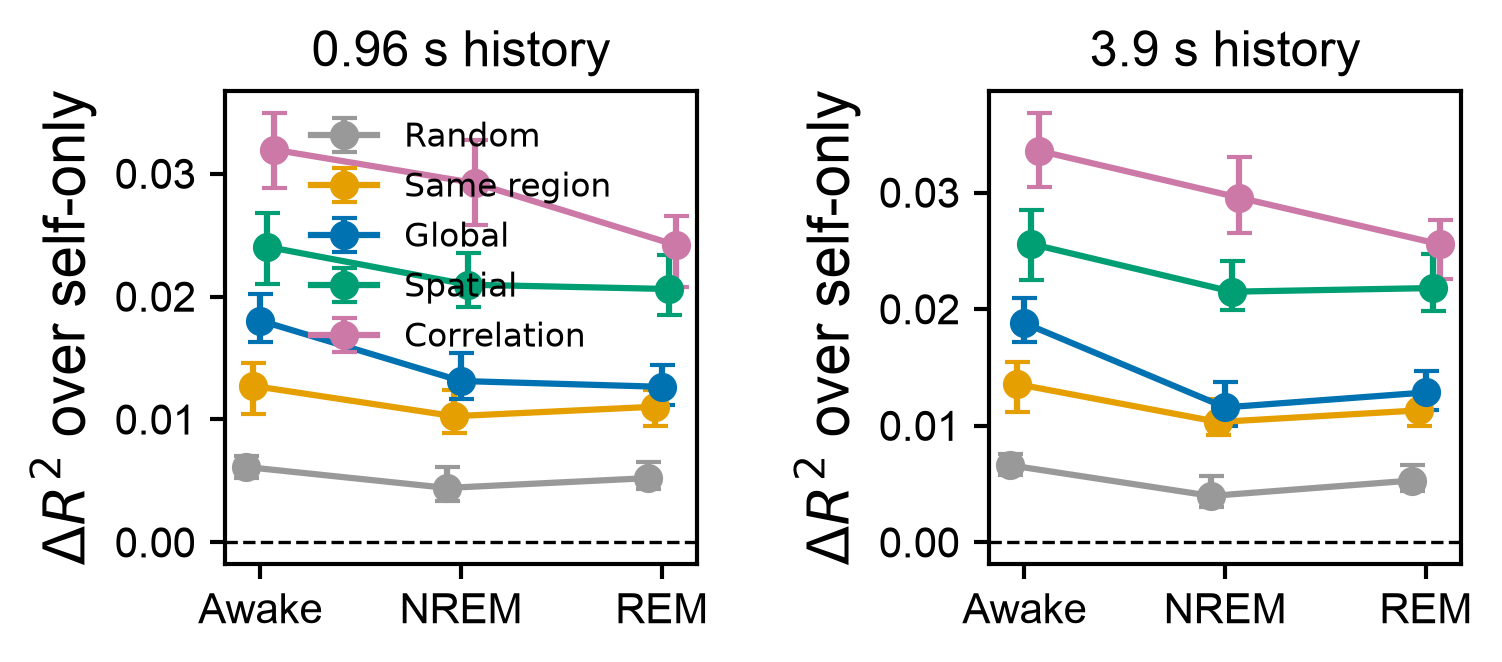

In [3]:
states = ['Awake', 'NREM', 'REM']
models = ['self_random', 'self_region', 'self_global', 'self_spatial', 'self_correlation']
labels = {'self_random': 'Random', 'self_region': 'Same region', 'self_global': 'Global', 'self_spatial': 'Spatial', 'self_correlation': 'Correlation'}
colors = {'self_random': '#999999', 'self_region': '#E69F00', 'self_global': '#0072B2', 'self_spatial': '#009E73', 'self_correlation': '#CC79A7'}
fig, axes = get_fig(RN=1, CN=2, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(np.asarray(axes).reshape(-1))
for history in [4, 16]:
    ax = next(ax_loader)
    part = results[(results.history == history) & results.model.isin(models)]
    x = np.arange(len(states))
    for offset, model in enumerate(models):
        stats = part[part.model == model].groupby('state').gain_over_self.agg(['mean', 'min', 'max']).reindex(states)
        position = x + (offset - 2) * .035
        ax.errorbar(position, stats['mean'], yerr=[stats['mean'] - stats['min'], stats['max'] - stats['mean']], marker='o', capsize=3, color=colors[model], label=labels[model])
    ax.axhline(0, color='black', ls='--', lw=.8)
    ax.set_xticks(x, states)
    ax.set_ylabel(r'$\Delta R^2$ over self-only')
    ax.set_title(f'{history / 4.146313525439001:.2g} s history')
    if history == 4:
        ax.legend(frameon=False, fontsize=8)
for suffix in ('png', 'svg', 'pdf'):
    fig.savefig(OUTPUT / f'graph_incremental_value.{suffix}', bbox_inches='tight', transparent=True)
plt.show()

## Interpretation

All context controls improve over self-only, including a random graph, so some gain comes from generic population information. Training-correlation neighbors add the most information, and spatial neighbors consistently exceed global, same-region, and random controls. This supports a reproducible local/functional predictive neighborhood. It does not identify synapses or direction because the graph is contemporaneous and may reflect shared local input, optical mixing, or latent waves.